<a href="https://colab.research.google.com/github/jamesreddeviltna/Open-House/blob/main/_EEG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## EEG Signal Analysis and Feature Extraction for Machine Learning

### 1. EEG signals and electrode locations

**Electroencephalography (EEG)** measures small voltage fluctuations at the scalp resulting primarily from synchronized electrical activity of populations of neurons. Multiple electrodes are placed at standardized locations so that activity from different regions of the brain can be compared.

In the common **10–20 electrode system**, labels indicate approximate brain regions:

- **Fp / F** — prefrontal and frontal regions
- **C** — central region
- **T** — temporal region
- **P** — parietal region
- **O** — occipital region

Thus, an EEG recording is naturally a **multichannel time series**

$
x_c(t),
$

where \(c\) identifies the EEG sensor. Different sensors may show different spectral activity because they sample electrical activity associated with different cortical regions. The spatial distribution of frequency-band power can therefore itself contain useful information for classification.

---


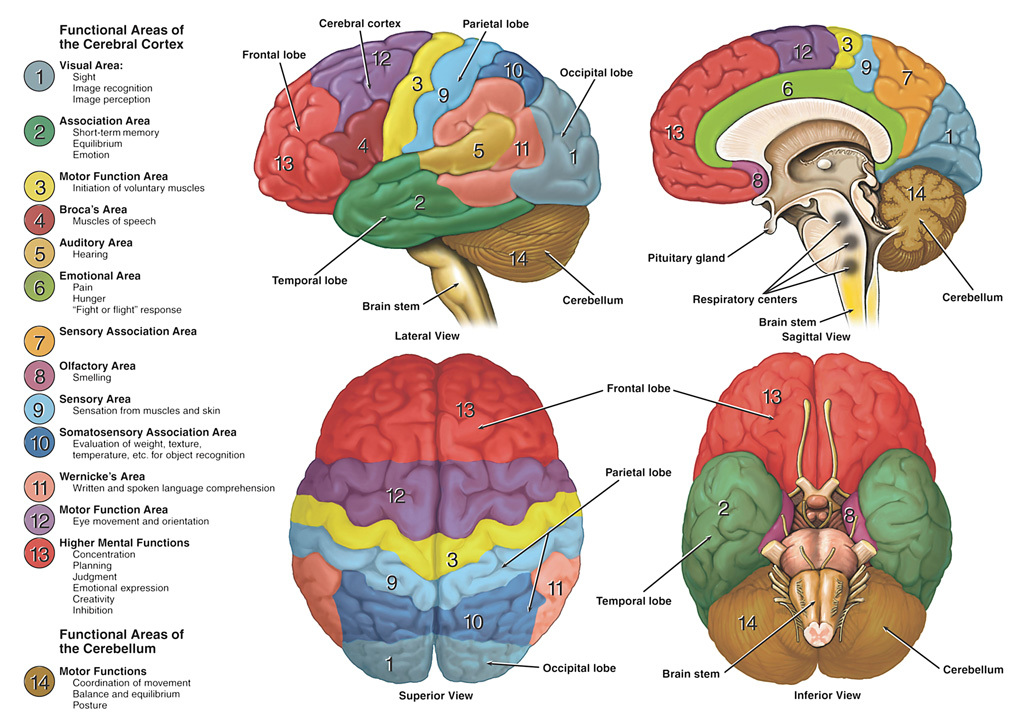

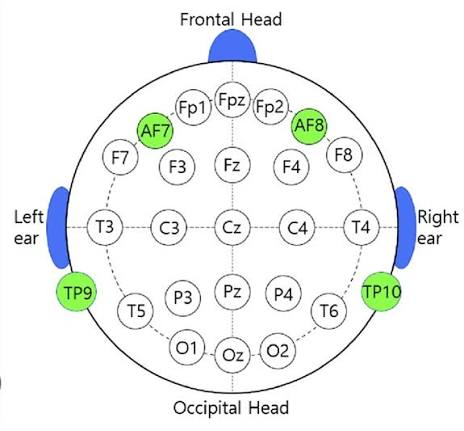


## 2. EEG brain-wave frequency bands

EEG activity is commonly separated into frequency bands. Approximate definitions are:

| Band | Typical frequency | Common association* |
|---|---:|---|
| **Delta ($\delta$)** | 0.5–4 Hz | Slow-wave/deep sleep |
| **Theta ($\theta$)** | 4–8 Hz | Drowsiness, memory-related activity |
| **Alpha ($\alpha$)** | 8–13 Hz | Relaxed wakefulness, often prominent posteriorly with eyes closed |
| **Beta ($\beta$)** | 13–30 Hz | Alertness and active processing |
| **Gamma ($\gamma$)** | 30–45+ Hz | Higher-frequency neural activity |

\*These are broad associations rather than one-to-one indicators of mental states. Band boundaries also vary somewhat between EEG studies.

A raw EEG signal contains a mixture of these frequencies:

$
x(t)
=
x_\delta(t)+x_\theta(t)+x_\alpha(t)
+x_\beta(t)+x_\gamma(t)+\text{noise}.
$

The objective of spectral analysis is therefore to determine **how much signal power occurs in each frequency range**.

---

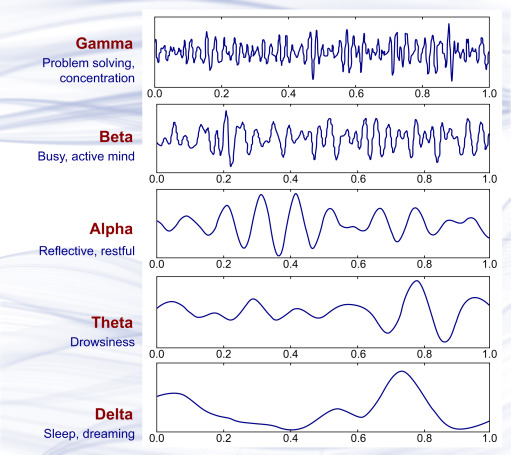

# 3. From EEG time series to frequency spectrum

Suppose a sensor records the discrete time series

$
x[n],\qquad n=0,1,\ldots,N-1
$

with sampling frequency \(f_s\).

The **Discrete Fourier Transform (DFT)** is

$
\boxed{
X[k]
=
\sum_{n=0}^{N-1}
x[n]e^{-i2\pi kn/N}
}
$

and the corresponding frequency of bin \(k\) is

$
\boxed{
f_k=\frac{k f_s}{N}.
}
$

The Fourier transform \(X[k]\) is complex. Its magnitude,

$
|X[k]|,
$

describes the amplitude associated with each frequency, while its squared magnitude is related to signal power:

$
P[k]\propto |X[k]|^2.
$

---



## 4. Power spectral density and Band Power

Rather than using a single FFT directly, EEG analysis commonly estimates the **power spectral density (PSD)**. $P_m(f)$ within a small segment $m$. Once the PSD has been obtained, the power of a brain-wave band is simply the **area underneath the PSD within that frequency interval**.

For a band extending from $f_1$ to $f_2$,

$
\boxed{
P_{\mathrm{band}}
=
\int_{f_1}^{f_2}P_m(f)\,df
}
$

and numerically,

$
\boxed{
P_{\mathrm{band}}
\approx
\sum_{f_k=f_1}^{f_2}
P_m(f)\Delta f .
}
$

Therefore,

$
P_\delta=\int_{0.5}^{4}P_m(f)\,df,
$

$
P_\theta=\int_{4}^{8}P_m(f)\,df,
$

$
P_\alpha=\int_{8}^{13}P_m(f)\,df,
$

$
P_\beta=\int_{13}^{30}P_m(f)\,df,
$

and, for example,

$
P_\gamma=\int_{30}P_m(f)\,df.
$

Thus, the colored regions underneath a PSD curve represent quantities that can be converted directly into numerical features.

Absolute EEG amplitude can differ substantially among sensors, subjects, and recordings. We can therefore also calculate **relative band power**:

$
\boxed{
R_i =
\frac{P_i}{P_{\mathrm{total}}}
}
$

where, for example,

$
R_\alpha =
\frac{P_\alpha}
{P_\delta+P_\theta+P_\alpha+P_\beta+P_\gamma}.
$

Relative power describes the **fraction of EEG spectral power contained within a particular frequency band** and can be useful when comparing recordings with different overall amplitudes.

---

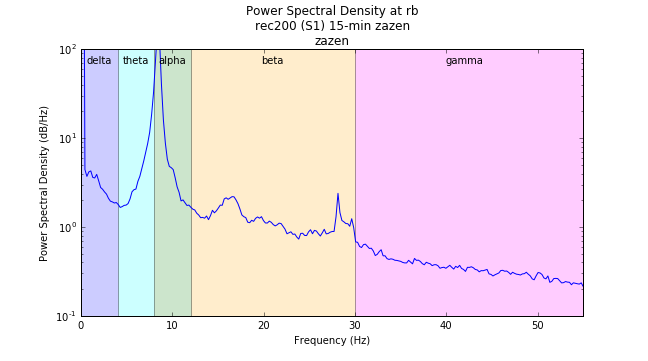

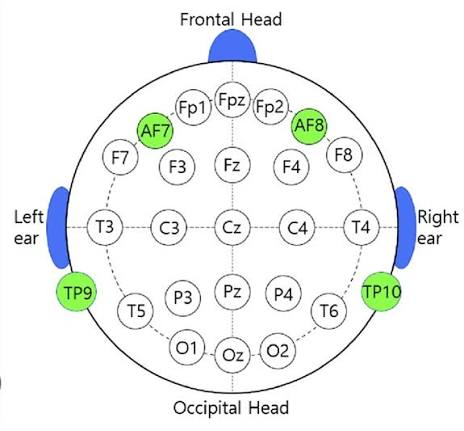

## Epileptic Seizure Recognition Dataset

https://www.kaggle.com/datasets/harunshimanto/epileptic-seizure-recognition

In [ ]:
# Download an EEG Dataset

!gdown --id 1Vpdd9xbmwOn0ZDUnStqq1U9Msvg5w_Cb -O eeg.csv

In [ ]:
# Install neurokit2 library for ECG and EEG processing

!pip install neurokit2

## Single signal preprocessing routine

In [ ]:
# library import
import pandas as pd
import numpy as np
import neurokit2 as nk
import matplotlib.pyplot as plt
import librosa

In [ ]:
import pandas as pd

# read the whole dataset: each column correspond to each sensor
df = pd.read_csv('eeg.csv')
df

In [ ]:
import numpy as np
import pandas as pd
import neurokit2 as nk
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Read the newly loaded eeg.csv dataset
df_new = pd.read_csv('eeg.csv')

# 2. Drop the first column ('Unnamed') as requested
if 'Unnamed' in df_new.columns:
    df_new = df_new.drop(columns=['Unnamed'])

# Get columns representing the 178 signal values (X1 to X178)
signal_cols = [col for col in df_new.columns if col != 'y']

# Extract signals and target label
signals = df_new[signal_cols].to_numpy()
y_new = df_new['y'].to_numpy()

print(f"Signals matrix shape: {signals.shape}")
print(f"Target distribution: {np.bincount(y_new)[1:]}")

In [ ]:
# showing sample data

index = 2
plt.plot(signals[index])
print("type", y_new[index])
plt.show()

In [ ]:
# 3. Extract relative band powers for each row (1 second, fs = 178 Hz)
fs_new = 178
bands = [
    (2.0, 4),  # Set lower bound to 2.0 Hz to prevent NaN in short 1s segments
    (4, 8),
    (8, 13),
    (13, 30),
    (30, 45)
]

relative_features = []

print("Extracting relative band powers...")
for i in range(len(signals)):
    signal = signals[i]

    # Calculate absolute power using neurokit2
    power = nk.signal_power(
        signal,
        frequency_band=bands,
        sampling_rate=fs_new
    )

    # Extract absolute values and fill any remaining NaNs with 0
    abs_powers = power.iloc[0].fillna(0).values
    total_power = np.sum(abs_powers)

    # Calculate relative powers (preventing division by zero)
    if total_power > 0:
        rel_powers = abs_powers / total_power
    else:
        rel_powers = np.zeros_like(abs_powers)

    relative_features.append(rel_powers)

# Construct the DataFrame
X_rel = pd.DataFrame(
    relative_features,
    columns=["Rel_Delta", "Rel_Theta", "Rel_Alpha", "Rel_Beta", "Rel_Gamma"]
)

print("Extraction complete.")
display(X_rel.head())

In [ ]:
# 4. Split dataset into train and test sets (80% train, 20% test)
X_train_rel, X_test_rel, y_train_rel, y_test_rel = train_test_split(
    X_rel, y_new, test_size=0.2, random_state=42, stratify=y_new
)

# 5. Train and evaluate the Random Forest model
rf_rel = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_rel.fit(X_train_rel, y_train_rel)

y_pred_rel = rf_rel.predict(X_test_rel)
accuracy_rel = accuracy_score(y_test_rel, y_pred_rel)

print(f"Classification Test Accuracy with Relative Band Powers: {accuracy_rel:.4f}\n")
print("Classification Report:")
print(classification_report(y_test_rel, y_pred_rel))

## Mathematical Definitions of Enriched Librosa Features

In our enriched classification pipeline, we incorporated six additional spectral and temporal descriptors using the `librosa` library. This section provides their physical meaning and formal mathematical definitions.

Let $X[k]$ be the Discrete Fourier Transform (DFT) magnitude (spectrum) of the windowed signal segment at bin index $k$, and let $f_k = k \cdot \frac{f_s}{N}$ represent the center frequency corresponding to bin $k$.

---

### 1. Spectral Centroid
* **Textual Definition:** Represents the "center of mass" of the power spectrum. It indicates where the dominant frequency components are concentrated and correlates strongly with the human perception of "brightness" or "sharpness" of a sound or signal.
* **Mathematical Definition:**
$$\text{Spectral Centroid} = \frac{\sum_{k} f_k \cdot |X[k]|}{\sum_{k} |X[k]|}$$

---

### 2. Spectral Rolloff
* **Textual Definition:** The frequency below which a specified percentage (commonly $85\%$) of the total spectral energy lies. It serves as a measure of the high-frequency content and shape of the spectral roll-off.
* **Mathematical Definition:**
$$\text{Spectral Rolloff} = f_{k_c} \quad \text{such that} \quad \sum_{k=0}^{k_c} |X[k]|^2 = \alpha \cdot \sum_{k=0}^{N-1} |X[k]|^2$$
*(where $\alpha$ is typically set to $0.85$)*

---

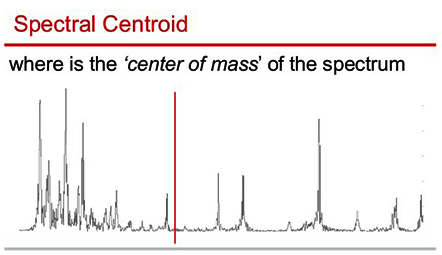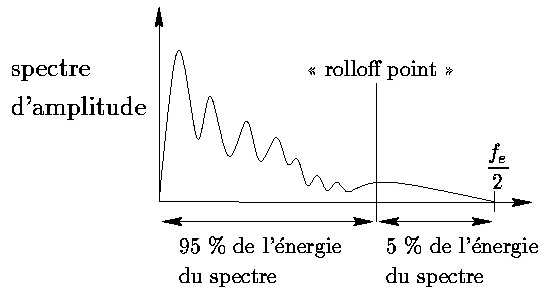



### 3. Spectral Bandwidth
* **Textual Definition:** Measures the width of the spectrum around its centroid. It characterizes the spread of the frequencies contained in the signal (i.e., whether they are concentrated tightly around the centroid or widely dispersed).
* **Mathematical Definition:**
$$\text{Spectral Bandwidth} = \left( \sum_{k} |X[k]| \cdot (f_k - f_{\text{centroid}})^2 \right)^{1/2}$$
*(where $f_{\text{centroid}}$ is the calculated Spectral Centroid)*

---

### 4. Root Mean Square (RMS)
* **Textual Definition:** A temporal measure that computes the square root of the arithmetic mean of the squared signal values. It directly quantifies the overall amplitude, signal power, and physical energy present in the time domain.
* **Mathematical Definition:**
$\text{RMS} = \sqrt{\frac{1}{M} \sum_{t=1}^{M} x[t]^2}$
*(where $x[t]$ is the amplitude of the signal at time step $t$ and $M$ is the frame length)*

---

### 5. Spectral Flatness
* **Textual Definition:** Measures the "noisiness" or tonal quality of a signal. It is calculated as the ratio of the geometric mean of the power spectrum to its arithmetic mean. A flatness close to $1.0$ resembles white noise (uniform power across frequencies), whereas a flatness close to $0.0$ indicates a highly tonal, peaky spectrum.
* **Mathematical Definition:**
$$\text{Spectral Flatness} = \frac{\exp \left( \frac{1}{K} \sum_{k=0}^{K-1} \ln |X[k]|^2 \right)}{\frac{1}{K} \sum_{k=0}^{K-1} |X[k]|^2}$$

---

### 6. Zero-Crossing Rate (ZCR)
* **Textual Definition:** The rate at which the signal amplitude changes sign (crosses the zero line) along the time-domain frame. It provides an easy, low-complexity estimation of high-frequency fluctuations and spectral properties.
* **Mathematical Definition:**
$$\text{ZCR} = \frac{1}{2(M-1)} \sum_{t=1}^{M-1} |\text{sign}(x[t]) - \text{sign}(x[t-1])|$$
*(where $\text{sign}(a) = 1$ if $a \ge 0$, and $-1$ if $a < 0$)*

In [ ]:
import numpy as np
import pandas as pd
import librosa
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Prepare lists for additional spectral and temporal features
spectral_centroids = []
spectral_rolloffs = []
spectral_bandwidths = []
rms_values = []
spectral_flatnesses = []
zcrs = []

print("Extracting extra features using librosa...")
for i in range(len(signals)):
    signal = signals[i].astype(float)

    # 1. Spectral Centroid
    cent = librosa.feature.spectral_centroid(y=signal, sr=fs_new)
    spectral_centroids.append(np.mean(cent))

    # 2. Spectral Rolloff
    rolloff = librosa.feature.spectral_rolloff(y=signal, sr=fs_new)
    spectral_rolloffs.append(np.mean(rolloff))

    # 3. Spectral Bandwidth
    bandwidth = librosa.feature.spectral_bandwidth(y=signal, sr=fs_new)
    spectral_bandwidths.append(np.mean(bandwidth))

    # 4. Root Mean Square (RMS)
    rms = librosa.feature.rms(y=signal)
    rms_values.append(np.mean(rms))

    # 5. Spectral Flatness
    flatness = librosa.feature.spectral_flatness(y=signal)
    spectral_flatnesses.append(np.mean(flatness))

    # 6. Zero-Crossing Rate (ZCR)
    zcr = librosa.feature.zero_crossing_rate(y=signal)
    zcrs.append(np.mean(zcr))

# Add the new features to the existing DataFrame
X_enriched = X_rel.copy()
X_enriched['Spectral_Centroid'] = spectral_centroids
X_enriched['Spectral_Rolloff'] = spectral_rolloffs
X_enriched['Spectral_Bandwidth'] = spectral_bandwidths
X_enriched['RMS'] = rms_values
X_enriched['Spectral_Flatness'] = spectral_flatnesses
X_enriched['Zero_Crossing_Rate'] = zcrs

print("Features extraction complete. Enriched dataset shape:", X_enriched.shape)
print("Preview of enriched features:")
display(X_enriched.head())


In [ ]:
# Split the enriched dataset (80% train, 20% test)
X_train_en, X_test_en, y_train_en, y_test_en = train_test_split(
    X_enriched, y_new, test_size=0.2, random_state=42, stratify=y_new
)

# Train and evaluate the new Random Forest model
rf_enriched = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_enriched.fit(X_train_en, y_train_en)

y_pred_en = rf_enriched.predict(X_test_en)
accuracy_en = accuracy_score(y_test_en, y_pred_en)

print(f"Classification Test Accuracy with Enriched Features: {accuracy_en:.4f}\n")
print("Classification Report:")
print(classification_report(y_test_en, y_pred_en))

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Get feature importances from the trained model
importances = rf_enriched.feature_importances_
feature_names = X_enriched.columns

# 2. Create a DataFrame for sorting and plotting
feat_importances = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("Feature Importances Ranked:")
display(feat_importances)

# 3. Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_importances, palette='viridis')
plt.title('Feature Importances from Enriched Random Forest Model')
plt.xlabel('Importance Value')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

# 1. Identify the top 3 features based on the previous importance analysis
top_features = ['RMS', 'Rel_Theta', 'Rel_Beta']

# 2. Set the target class label to 1 directly
target_class = 1

# 3. Create the Partial Dependence Plot
print(f"Computing and plotting PDP profiles for {top_features} against class '{target_class}'...")
fig, ax = plt.subplots(figsize=(15, 4))

PartialDependenceDisplay.from_estimator(
    estimator=rf_enriched,
    X=X_train_en,
    features=top_features,
    target=target_class,
    grid_resolution=50,
    ax=ax
)

plt.suptitle(f"Partial Dependence Plots for Top 3 Features (Target Class: {target_class})", y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
import librosa
import neurokit2 as nk

# 1. Define Class Interpretations based on the dataset specifications
class_definitions = {
    1: "Seizure activity (recording of seizure activity)",
    2: "Tumor area (EEG from the area where tumor was identified)",
    3: "Healthy area (EEG from healthy brain region)",
    4: "Eyes closed (EEG with patient's eyes closed)",
    5: "Eyes open (EEG with patient's eyes open)"
}

# 2. Interactive widget callback function
def inspect_signal(index):
    clear_output(wait=True)

    # Display Class Definitions reference
    html_defs = "<h3>Class Definitions:</h3><ul>"
    for cl, desc in class_definitions.items():
        html_defs += f"<li><b>Class {cl}:</b> {desc}</li>"
    html_defs += "</ul><hr>"
    display(HTML(html_defs))

    # Get the raw signal
    signal = signals[index].astype(float)
    true_label = int(y_new[index])

    # Plot signal waveform
    plt.figure(figsize=(10, 3.5))
    plt.plot(signal, color='#1f77b4', lw=1.5)
    plt.title(f"EEG Signal (Index: {index}) | True Class: {true_label} ({class_definitions[true_label].split(' ')[0]})", fontsize=12)
    plt.xlabel("Sample Points (1s duration, fs=178Hz)")
    plt.ylabel("Amplitude (\mu V)")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Extract Features on the fly
    # Relative band powers
    fs_new = 178
    bands = [(2.0, 4), (4, 8), (8, 13), (13, 30), (30, 45)]
    power = nk.signal_power(signal, frequency_band=bands, sampling_rate=fs_new)
    abs_powers = power.iloc[0].fillna(0).values
    total_power = np.sum(abs_powers)
    rel_powers = abs_powers / total_power if total_power > 0 else np.zeros_like(abs_powers)

    # Librosa extra features
    cent = np.mean(librosa.feature.spectral_centroid(y=signal, sr=fs_new))
    rolloff = np.mean(librosa.feature.spectral_rolloff(y=signal, sr=fs_new))
    bandwidth = np.mean(librosa.feature.spectral_bandwidth(y=signal, sr=fs_new))
    rms = np.mean(librosa.feature.rms(y=signal))
    flatness = np.mean(librosa.feature.spectral_flatness(y=signal))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y=signal))

    # Structure as a DataFrame row
    extracted_features = {
        'Rel_Delta': rel_powers[0],
        'Rel_Theta': rel_powers[1],
        'Rel_Alpha': rel_powers[2],
        'Rel_Beta': rel_powers[3],
        'Rel_Gamma': rel_powers[4],
        'Spectral_Centroid': cent,
        'Spectral_Rolloff': rolloff,
        'Spectral_Bandwidth': bandwidth,
        'RMS': rms,
        'Spectral_Flatness': flatness,
        'Zero_Crossing_Rate': zcr
    }

    feat_df = pd.DataFrame([extracted_features])

    # Display Features Table
    display(HTML("<h3>Extracted Feature Values:</h3>"))
    display(feat_df.style.hide(axis='index'))

    # Predict class probabilities
    probs = rf_enriched.predict_proba(feat_df)[0]
    classes = rf_enriched.classes_

    # Display predictions
    html_pred = "<h3>Model Classification Probability:</h3><table border='1' style='border-collapse:collapse; text-align:left; width:100%;'>"
    html_pred += "<tr style='background-color:#f2f2f2;'><th>Class</th><th>State Description</th><th>Probability</th></tr>"

    for cl, prob in zip(classes, probs):
        highlight = "font-weight:bold; background-color:#e2f0d9;" if cl == true_label else ""
        html_pred += f"<tr style='{highlight}'><td>Class {cl}</td><td>{class_definitions[cl]}</td><td>{prob*100:.2f}%</td></tr>"
    html_pred += "</table>"
    display(HTML(html_pred))

# Setup the slider and interactive layout
index_slider = widgets.IntSlider(
    value=2,
    min=0,
    max=len(signals) - 1,
    step=1,
    description='Signal Index:',
    layout=widgets.Layout(width='60%'),
    continuous_update=False
)

ui = widgets.VBox([widgets.HTML("<h2>Interactive EEG Signal Profiler</h2>"), index_slider])
out = widgets.interactive_output(inspect_signal, {'index': index_slider})

display(ui, out)

# 5. Spatial information: band power at different EEG sensors

An important point illustrated by the scalp maps is that brain-wave activity is not necessarily distributed uniformly across the scalp.

We therefore should not simply calculate one alpha power for the entire EEG recording. Instead, for each sensor \(c\), calculate

$
\boxed{
P_{\delta,c},
P_{\theta,c},
P_{\alpha,c},
P_{\beta,c},
P_{\gamma,c}
}
$

separately.

For example, sensor **O1** might give

$
[P_{\delta,O1},
P_{\theta,O1},
P_{\alpha,O1},
P_{\beta,O1},
P_{\gamma,O1}],
$

while **F3** gives another five values:

$
[P_{\delta,F3},
P_{\theta,F3},
P_{\alpha,F3},
P_{\beta,F3},
P_{\gamma,F3}].
$

The ML model therefore retains both **spectral information** (which frequency band?) and **spatial information** (which electrode?).

---

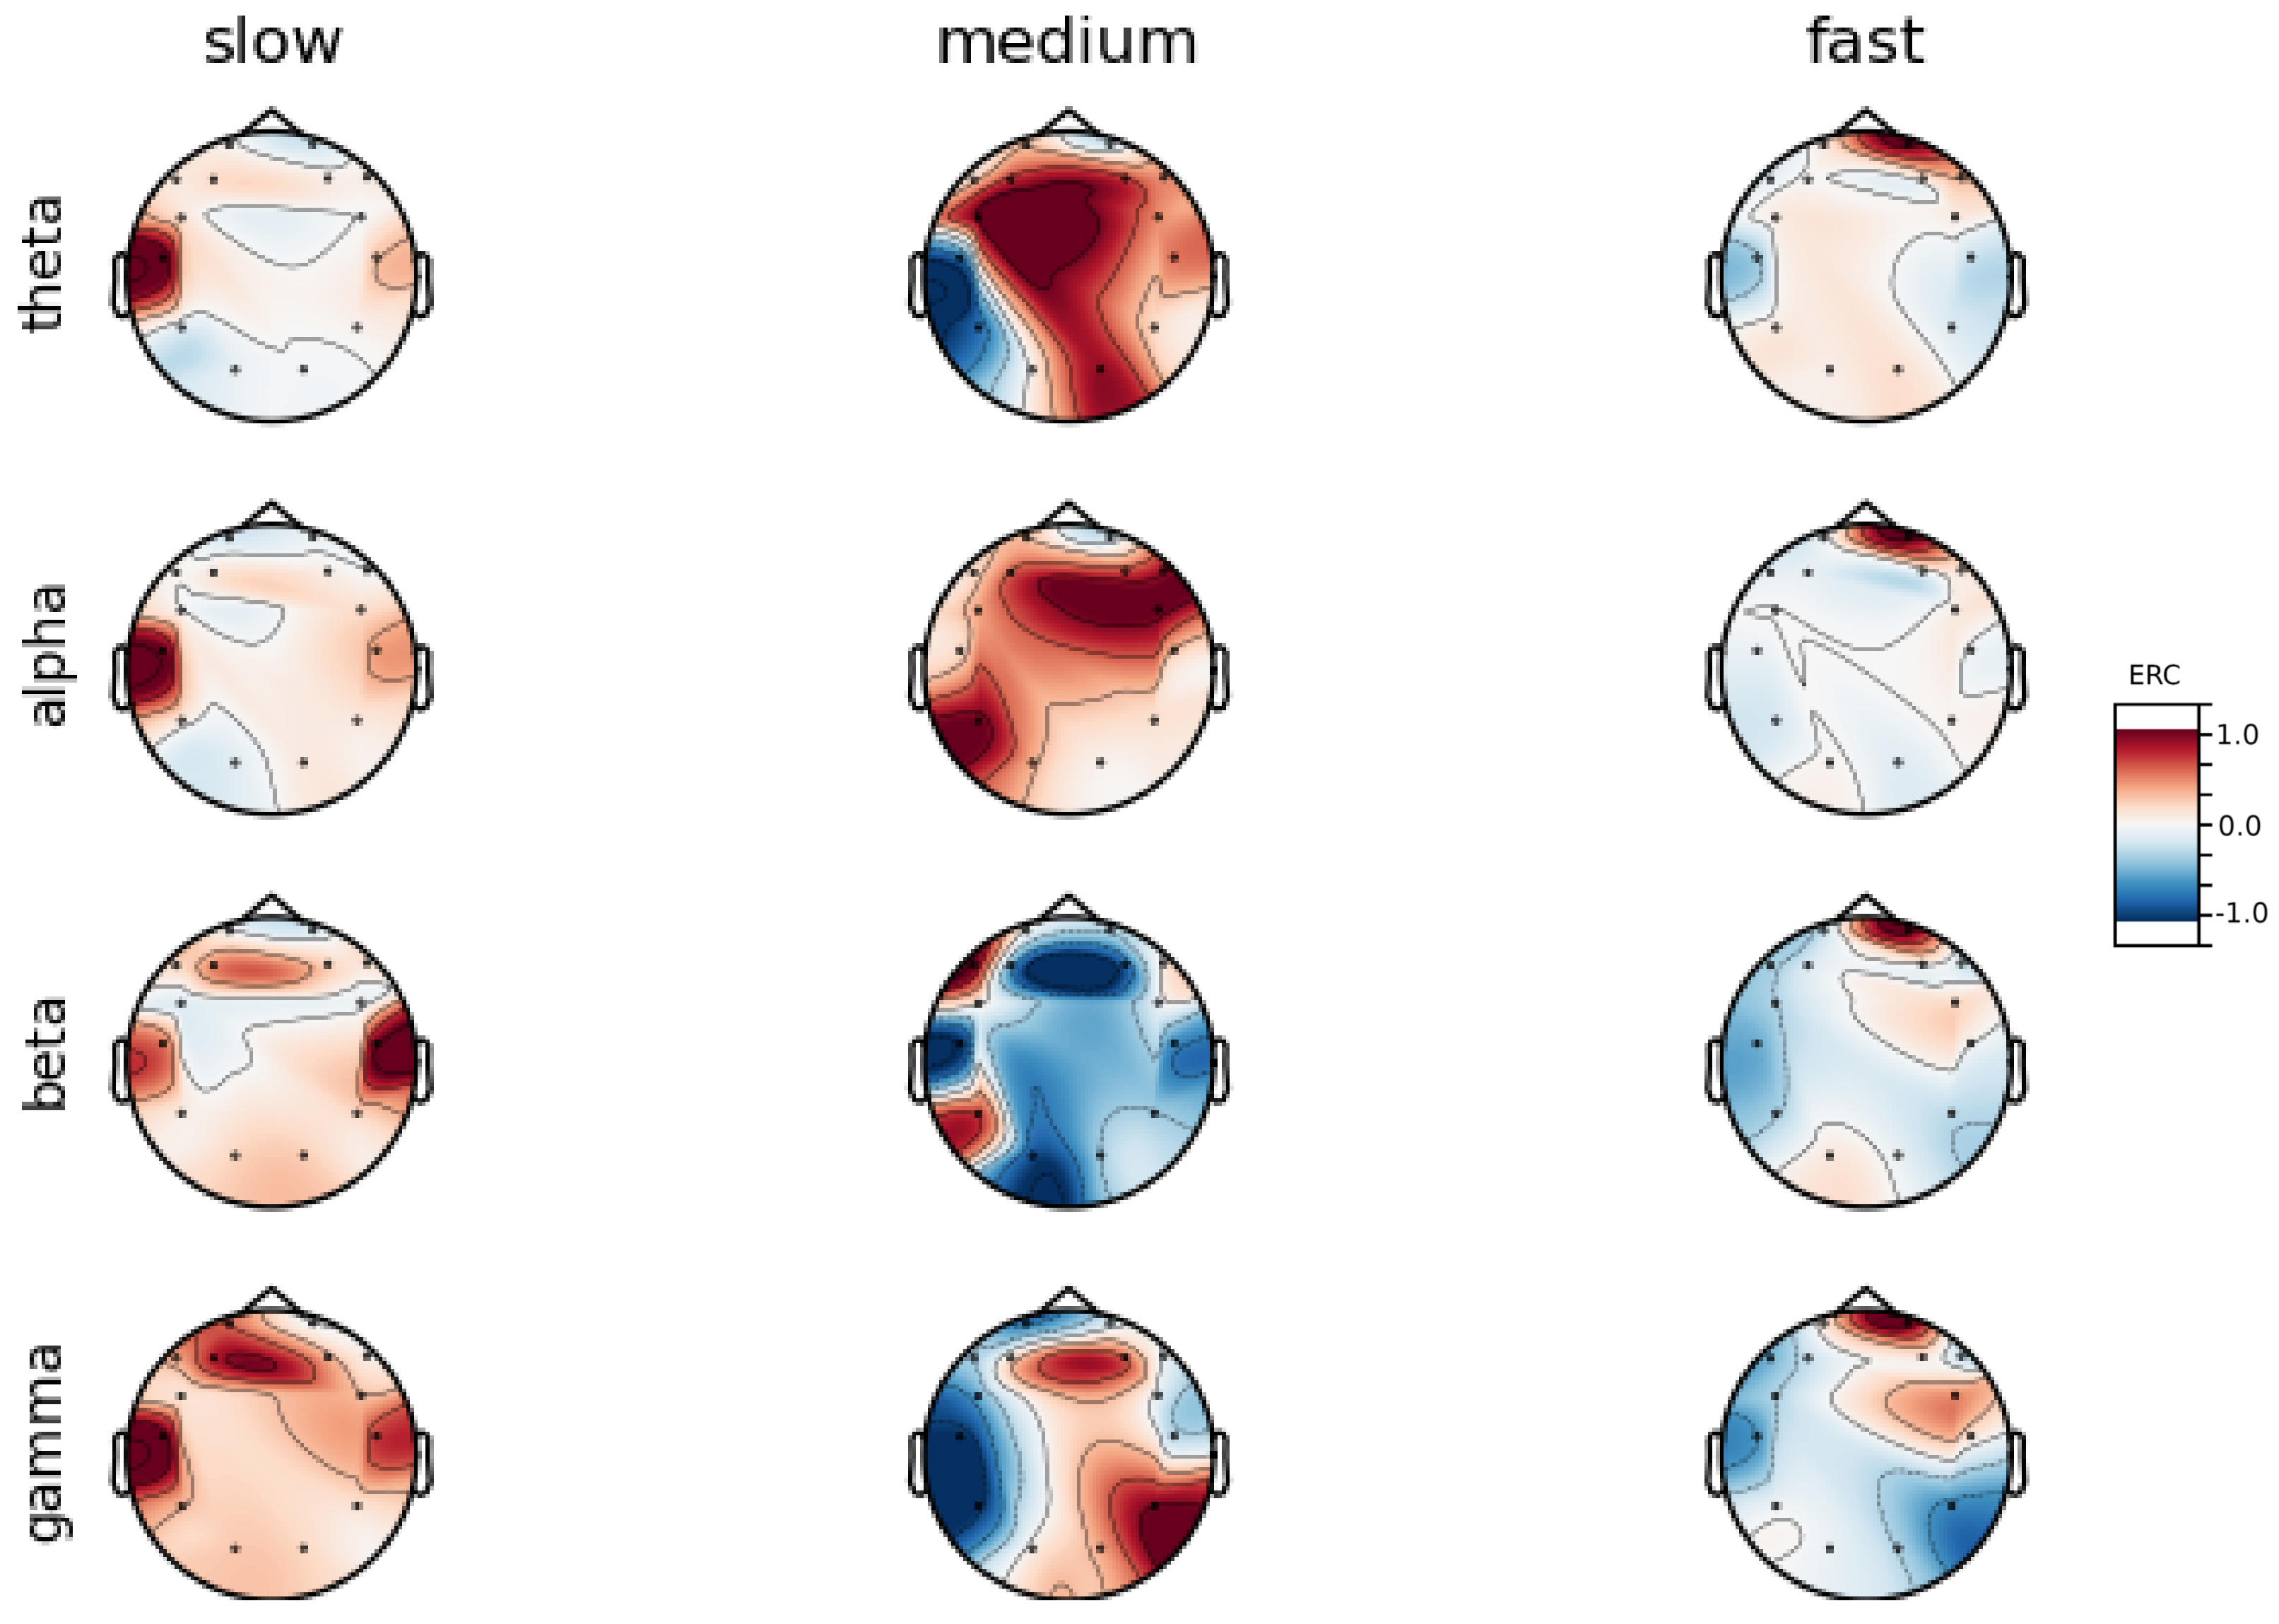



# 6. Preparing a Long EEG data for ML

A long EEG recording should first be divided into shorter time windows, for example **4-second clips**:

$
\text{continuous EEG}
\rightarrow
\boxed{0-4~s}
\boxed{2-6~s}
\boxed{4-8~s}
\cdots
$

where the example above uses 50% overlap.

For each clip and each EEG channel:

$
x_c(t)
\xrightarrow{\mathrm{FFT/PSD}}
S_{xx,c}(f)
\xrightarrow{\mathrm{integration}}
\left[
P_{\delta,c},
P_{\theta,c},
P_{\alpha,c},
P_{\beta,c},
P_{\gamma,c}
\right].
$

If there are \(C\) EEG sensors, one time window produces

$
\boxed{5C\text{ features}}.
$

For example, 14 EEG channels produce

$
14\times5=70
$

band-power features.

The resulting ML table has the form:

| Window | F3 δ | F3 θ | F3 α | F3 β | F3 γ | F4 δ | ... | O2 γ | Target |
|---|---:|---:|---:|---:|---:|---:|---|---:|---|
| 1 | ... | ... | ... | ... | ... | ... | ... | ... | Class A |
| 2 | ... | ... | ... | ... | ... | ... | ... | ... | Class B |
| 3 | ... | ... | ... | ... | ... | ... | ... | ... | Class A |

This feature matrix can then be supplied to classifiers such as **logistic regression, Random Forest, SVM, or neural networks**.

### Overall EEG-to-ML pipeline

$
\boxed{\text{Multichannel EEG}}
\rightarrow
\boxed{\text{short time windows}}
\rightarrow
\boxed{\text{FFT / PSD}}
\rightarrow
\boxed{\text{band integration}}
\rightarrow
\boxed{\delta,\theta,\alpha,\beta,\gamma
\text{ power per sensor}}
\rightarrow
\boxed{\text{ML classifier}}
$

The key idea is that instead of asking the ML algorithm to interpret thousands of raw EEG voltage measurements directly, we convert each EEG window into a smaller set of **physically and physiologically interpretable features**. The model can then learn patterns such as *increased alpha power at posterior sensors together with decreased beta power at frontal sensors*, rather than simply learning from individual voltage samples.

For your course, this also provides a particularly clear connection between **Fourier analysis learned in physics and feature engineering in machine learning**: the FFT transforms the measured time-domain signal into frequency information, integration of the PSD produces physically meaningful quantities, and those quantities become the input variables \(X_1,X_2,\ldots,X_p\) of an ML model.

# Assignment
**EEG Datasets:**

https://www.kaggle.com/datasets/birdy654/eeg-brainwave-dataset-mental-state?select=mental-state.csv

https://www.kaggle.com/datasets/robikscube/eye-state-classification-eeg-dataset/code

https://www.kaggle.com/datasets/jbouv27/eeg

https://www.kaggle.com/datasets/quands/eeg-dataset

https://www.kaggle.com/datasets/samnikolas/eeg-dataset

**Non-EEG Datasets:**

ECG (heartbeats) - Need segmentation / MFCC can be used along with some other features
https://www.kaggle.com/datasets/shayanfazeli/heartbeat

https://www.kaggle.com/datasets/sadmansakib7/ecg-arrhythmia-classification-dataset

https://www.kaggle.com/datasets/imnikhilanand/heart-attack-prediction

Breath - MFCC can be used along with some other features



**WARNING: All datasets need different ways of cleaning / preparing the data for ML training. Do understand the structure well!**